In [1]:
import xgboost as xgb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import talib as ta
import numpy as np
import optuna

from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from typing import Union
from typing import Dict

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
def test_plot(y_pred, y_test) -> None:
    df = pd.DataFrame({'Date': y_test.index, 'True_close': y_test.values, 'Pred_close': y_pred})

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='Date', y='True_close', color='blue', label='Фактические значения (y_test)', linewidth=2)
    sns.lineplot(data=df, x='Date', y='Pred_close', color='red', marker='o', label='Предсказанные значения (y_pred)', linewidth=2)
    plt.title('Сравнение фактических и предсказанных значений', fontsize=14, fontweight='bold')
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Значения', fontsize=12)
    plt.legend(fontsize=10)
    plt.xticks(rotation=45)
    
    plt.gcf().autofmt_xdate()
    
    plt.tight_layout()
    plt.show()

In [23]:
def model_time_series_validation(
    model, 
    params: Dict[str, Union[int, float, str]]) -> float:
    global X_train, y_train, X_test, y_test, best_params, least_error
    
    tscv = TimeSeriesSplit(n_splits=3)

    scores = []
    
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        if type(model) is xgb.XGBRegressor:
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        else:
            model.fit(X_tr, y_tr)
        
        scores.append(mean_absolute_percentage_error(model.predict(X_val), y_val))

    if type(model) is xgb.XGBRegressor:
        model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
    else:
        model.fit(X_train, y_train)

    test_error = mean_absolute_percentage_error(model.predict(X_test), y_test)
    train_error = np.mean(scores)

    if least_error is None or least_error > test_error:
        least_error = test_error
        best_params = params
    
    print(f'Train error: {train_error}; Test error: {test_error}')
    print(params)

    return train_error

In [24]:
def load_sberbank() -> pd.DataFrame:
    df = pd.read_csv(r'..\..\resource\sberbank_stock_prices.csv', delimiter=';', dtype={'<DATE>' : str})
    df = df[['<DATE>', '<CLOSE>']]
    name_map = {column:column[1:-1].capitalize() for column in df.columns.tolist()}
    df = df.rename(columns=name_map)
    df['Date'] = pd.to_datetime(df['Date'], format='%y%m%d')
    df.set_index('Date', inplace=True)

    return df

In [25]:
def add_key_rate(df: pd.DataFrame) -> pd.DataFrame:
    df_rate = pd.read_csv(r'..\..\resource\cb_rate.csv', parse_dates=['Дата'])
    df_rate = df_rate.set_index('Дата')
    df.index = pd.to_datetime(df.index)
    df_rate = df_rate.shift(1).pct_change()
    df = df.join(df_rate['Ставка'], how='left')
    df.rename(columns={'Ставка': 'Rate'}, inplace=True)
    return df

In [26]:
def add_moscow_index(df: pd.DataFrame) -> pd.DataFrame:
    df_index = pd.read_csv(r'..\..\resource\security.csv', parse_dates=['TRADEDATE'], delimiter=';', decimal=',')
    df_index = df_index.set_index('TRADEDATE')
    df_index.rename(columns={'CLOSE': 'index_close'}, inplace=True)
    df_index = df_index.shift(1)
    df = df.join(df_index['index_close'], how='left')
    return df

In [27]:
def create_lags(df: pd.DataFrame, column: str, n_lags: int) -> pd.DataFrame:
    new_df = df.copy()
    for lag in range(1, n_lags + 1):
        new_df[f'{column}_lag_{lag}'] = new_df[column].shift(lag)

    return new_df

In [28]:
def create_ta_features(df: pd.DataFrame) -> pd.DataFrame:
    NUMBER_OF_LAGS = 4
    ROLLING_STD = 11
    ROLLING_MEAN = 11
    EMA_TIME_PERIOD = 9
    RSI_TIME_PERIOD = 9
    TARGET_NAME = 'Close'

    new_df = df.copy()
    new_df = add_key_rate(new_df)
    new_df = create_lags(new_df, TARGET_NAME, NUMBER_OF_LAGS)
    new_df[f'EMA_{EMA_TIME_PERIOD}'] = ta.EMA(new_df.Close, timeperiod=EMA_TIME_PERIOD)
    new_df['ROC_5'] = ta.ROC(new_df[TARGET_NAME].shift(1), timeperiod=5)
    new_df[f'RSI_{RSI_TIME_PERIOD}'] = ta.RSI(new_df.Close, timeperiod=RSI_TIME_PERIOD)
    new_df[f'Std_{ROLLING_STD}'] = new_df[TARGET_NAME].shift(1).rolling(ROLLING_STD).std()
    new_df[f'Mean_{ROLLING_MEAN}'] = new_df[TARGET_NAME].shift(1).rolling(ROLLING_MEAN).mean()
    new_df['Price_change'] = new_df[TARGET_NAME].shift(1).pct_change()
    new_df.dropna(inplace=True)

    return new_df

In [29]:
TARGET_COLUMN = 'Close'

data = load_sberbank()
data = create_ta_features(data)
X, y = data.drop(TARGET_COLUMN, axis=1), data[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [30]:
data

,Close,Rate,Close_lag_1,Close_lag_2,Close_lag_3,Close_lag_4,EMA_9,ROC_5,RSI_9,Std_11,Mean_11,Price_change
Date,,,,,,,,,,,,
2020-09-16,231.06,0.0,231.50,227.37,221.07,220.60,225.530684,6.348769,55.851991,4.462872,222.570909,0.018164
2020-09-17,231.46,0.0,231.06,231.50,227.37,221.07,226.716548,5.990826,56.609270,4.944471,222.881818,-0.001901
2020-09-18,230.30,0.0,231.46,231.06,231.50,227.37,227.433238,4.922937,53.609179,5.574775,223.690000,0.001731
2020-09-21,226.25,0.0,230.30,231.46,231.06,231.50,227.196590,4.175148,44.372598,5.590967,224.779091,-0.005012
2020-09-22,229.88,0.0,226.25,230.30,231.46,231.06,227.733272,-0.492589,52.606327,5.537767,225.146364,-0.017586
...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-28,310.82,0.0,312.78,311.79,311.42,311.84,312.366046,0.233937,41.652580,2.477747,313.289091,0.003175
2025-08-29,310.04,0.0,310.82,312.78,311.79,311.42,311.900837,-0.473903,39.143845,2.511923,312.911818,-0.006266
2025-08-30,309.92,0.0,310.04,310.82,312.78,311.79,311.504669,-0.577219,38.740003,1.874051,312.153636,-0.002509


In [31]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'C': trial.suggest_float('C', 1e3, 1e4),
        'epsilon': trial.suggest_float('epsilon', 0.01, 5.0),
        'kernel': trial.suggest_categorical('kernel', ['rbf'])
    }

    model = Pipeline([
        ('scaler', MinMaxScaler()),
        ('svr', SVR(**params))
    ])
    
    return model_time_series_validation(model, params)

In [32]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.11906166150107196; Test error: 0.006501581782065983
{'C': 7434.380213325007, 'epsilon': 4.247209049527996, 'kernel': 'rbf'}
Train error: 0.11705887400273314; Test error: 0.005396463164771688
{'C': 8816.860628569237, 'epsilon': 3.1645149673802293, 'kernel': 'rbf'}
Train error: 0.11513101988898501; Test error: 0.004524010206256795
{'C': 9438.888456368588, 'epsilon': 2.516987795635252, 'kernel': 'rbf'}
Train error: 0.11325043068055053; Test error: 0.00305387493721969
{'C': 3893.7168602701227, 'epsilon': 0.05937791788908213, 'kernel': 'rbf'}
Train error: 0.1134443806270467; Test error: 0.0030528268654777956
{'C': 5112.939684779897, 'epsilon': 0.054051395019149365, 'kernel': 'rbf'}
Train error: 0.11785898030368737; Test error: 0.006081080049564579
{'C': 4256.784872437036, 'epsilon': 3.8691770389543203, 'kernel': 'rbf'}
Train error: 0.1200054063984241; Test error: 0.006878885319265214
{'C': 6235.609724032349, 'epsilon': 4.593435347839933, 'kernel': 'rbf'}
Train error: 0.114894

In [33]:
model = Pipeline([
    ('scaler', MinMaxScaler()),
    ('svr', SVR(**best_params))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.0030528268654777956


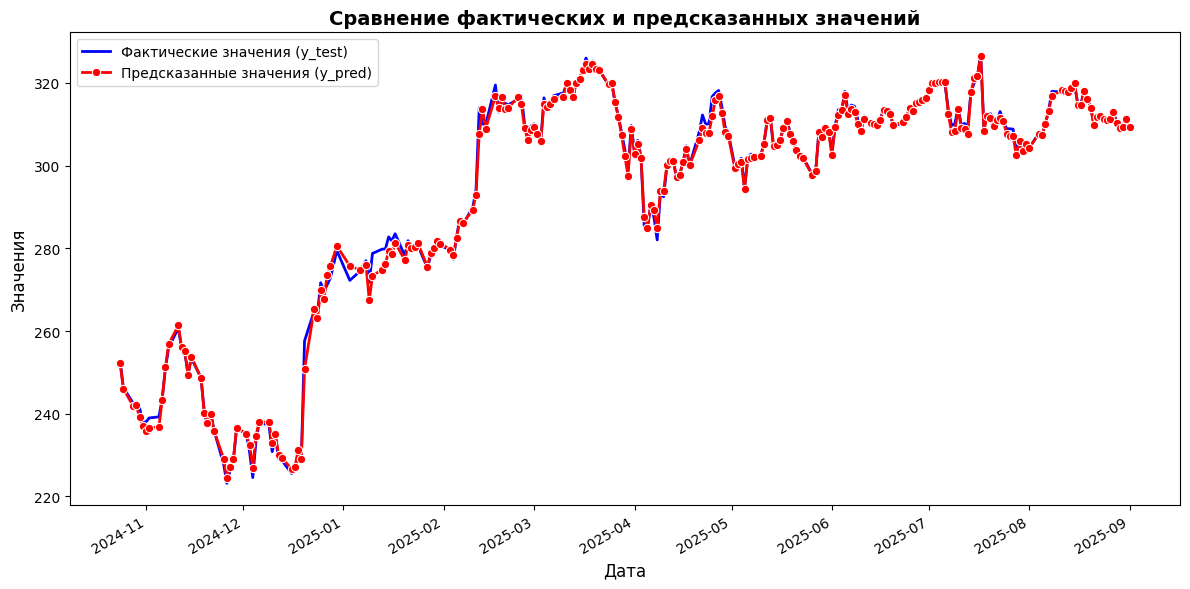

In [34]:
test_plot(y_pred, y_test)

In [67]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        'max_samples': trial.suggest_float('max_samples', 0.4, 0.9),
        'max_features': trial.suggest_categorical('max_features', ['sqrt']),
        'n_jobs': -1
    }

    model = RandomForestRegressor(**params)
    
    return model_time_series_validation(model, params)

In [68]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.09727534457165778; Test error: 0.009884033156468132
{'n_estimators': 1570, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_samples': 0.7931322105392846, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.0973859859071821; Test error: 0.010093030926082257
{'n_estimators': 821, 'max_depth': 8, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_samples': 0.6821602314975309, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.09867799694031819; Test error: 0.013032110752446991
{'n_estimators': 1494, 'max_depth': 5, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_samples': 0.8837273145655324, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.10212260041311427; Test error: 0.014298508239250607
{'n_estimators': 1535, 'max_depth': 4, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_samples': 0.8775057181042987, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.1012477839916439; Test error: 0.014643604726179234
{'n_estimators': 1604, 'max_dep

In [ ]:
model = RandomForestRegressor(**{'n_estimators': 1359, 'max_depth': 10, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_samples': 0.8314810760830686, 'max_features': 'sqrt', 'n_jobs': -1})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.009697942024718445


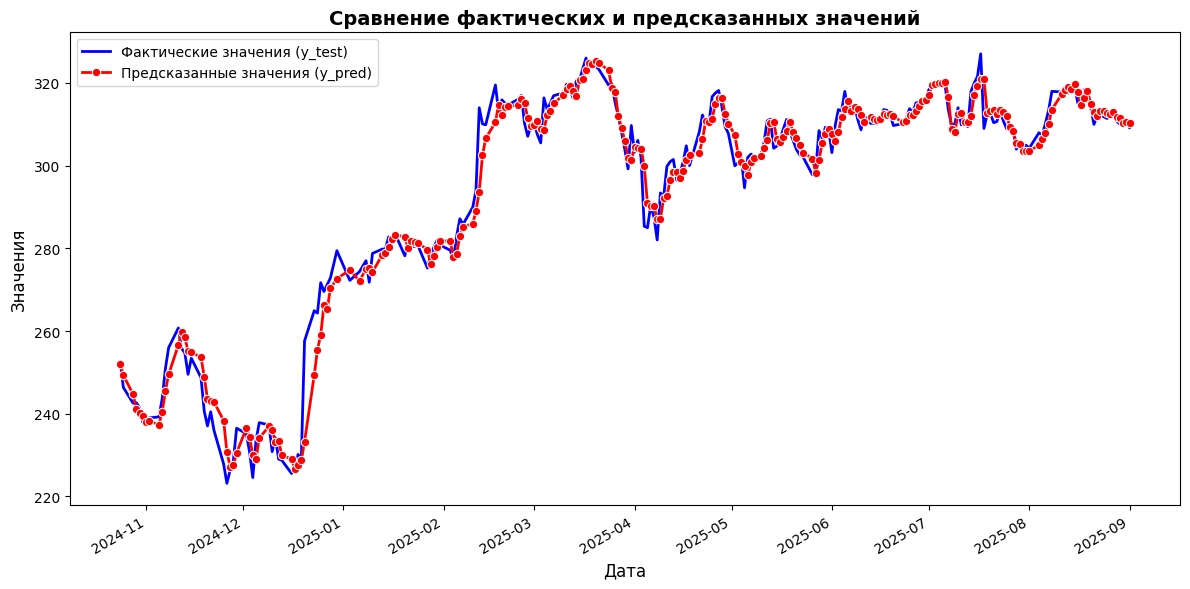

In [76]:
test_plot(y_pred, y_test)

In [77]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'tree_method': trial.suggest_categorical('tree_method', ['exact']),
        'n_estimators': trial.suggest_int('n_estimators', 1500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'min_child_weight': trial.suggest_float('min_child_weight', 5.0, 15.0, log=True),
        'learning_rate': trial.suggest_categorical('learning_rate', [0.1]),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 0.9),
        'reg_lambda': trial.suggest_float('reg_lambda', 300, 500, log=True),
        'early_stopping_rounds': trial.suggest_categorical('early_stopping_rounds', [100]),
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    
    return model_time_series_validation(model, params)

In [82]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.091824911544419; Test error: 0.00944526596107518
{'tree_method': 'exact', 'n_estimators': 1955, 'max_depth': 7, 'min_child_weight': 11.789835078485858, 'learning_rate': 0.1, 'subsample': 0.7749079241178359, 'colsample_bytree': 0.773574196907063, 'reg_lambda': 429.4036592603314, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.09121919578457116; Test error: 0.009435788168080429
{'tree_method': 'exact', 'n_estimators': 1978, 'max_depth': 6, 'min_child_weight': 9.652496021352938, 'learning_rate': 0.1, 'subsample': 0.8001845347439215, 'colsample_bytree': 0.8562361903588795, 'reg_lambda': 395.90671496730994, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.0924005362363799; Test error: 0.009374460776715882
{'tree_method': 'exact', 'n_estimators': 1685, 'max_depth': 6, 'min_child_weight': 7.128885720893082, 'learning_rate': 0.1, 'subsample': 0.7716547698252512, 'colsample_bytree': 0.7082931512716245, 'reg_lambda': 328.58863465371775, 'early_stopping_rounds'

In [81]:
model = xgb.XGBRegressor(**best_params)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.00910017521719176


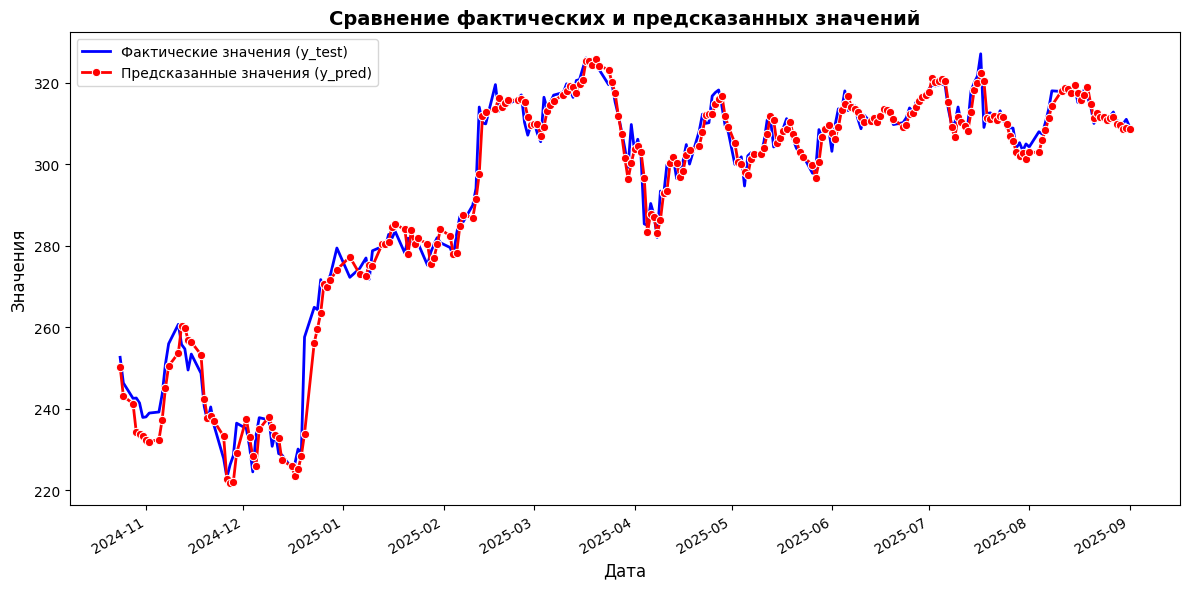

In [46]:
test_plot(y_pred, y_test)